<div style="text-align: center; background: white; padding: 10px; display: inline-block; width: 100%;">
    <img src="logo_cc.png" width="400">
</div>

## Introduction (Exploratory Data Analysis) :
This project is a professional collaboration with `Ora Technologies` to build a machine learning model for their money-transferring application , `Ora Cash`. The primary goal is to predict user churn and identify at-risk users who are likely to delete their accounts. By understanding the factors contributing to churn, we aim to provide actionable insights to prevent account deletions and increase user activity on the app.

`Ora Cash` is a financial application that allows users to transfer money seamlessly. However, like many subscription-based services, retaining users is a critical challenge. Users may delete their accounts for various reasons, including: Dissatisfaction with the service , Switching to a competitor , No longer needing the service.

To address this, we will analyze `user` behavior and `transaction` data to identify patterns and features that contribute to churn. The insights derived from this analysis will help Ora Technologies implement targeted interventions to retain users and enhance their engagement with the app.

### Project Goals
The key objectives of this project are:
1. Build a predictive model to identify users at risk of churning.
2. Analyze and visualize important features contributing to churn.
3. Provide actionable insights to help Ora Technologies:
    - Retain at-risk users by implementing targeted interventions.
    - Increase user activity and engagement on the Ora Cash application.

By achieving these goals, we aim to enhance user retention and drive growth for Ora Technologies.

## Understanding the Datasets

### Dataset descriptions
For this project, we are working with two datasets provided by Ora Technologies : (1) a `users` dataset containing profile information (e.g., creation date, last activity, account deletion status) and (2) a `transactions` dataset recording all financial interactions (e.g., payment timestamps, amounts, methods) within Ora Cash application. The goal is to merge these datasets to analyze user behavior and predict churn—whether a user will delete their account in the future. By engineering features like transaction frequency, spending trends, and inactivity periods, we’ll build a model to identify at-risk users before they churn.

In [125]:
import pandas as pd
pd.set_option('display.max_colwidth', None)

In [126]:
# Users dataset description
users_descriptions = pd.read_csv("Users_descriptions.csv")
users_descriptions.style.set_properties(**{'text-align': 'left'})

,Column_Name,Description
0,User_Id,Unique identifier for the user
1,Phone_Number,User's phone number for authentication and contact
2,User_Type,"Type of user (CUSTOMER, MERCHANT)"
3,Gender,"User's gender (male, female)"
4,Created_At,Timestamp when the user account was created
5,Updated_At,Timestamp when the user account was last updated
6,Deleted_At,Timestamp when the user account was deleted (soft delete)
7,First_Name,User's first name
8,Last_Online,Timestamp when the user was last online
9,Is_Online,Boolean indicating if the user is currently online


In [127]:
# Transactions dataset description
transactions_descriptions = pd.read_csv("Transactions_descriptions.csv")
transactions_descriptions.style.set_properties(**{'text-align': 'left'})

,Column_Name,Description
0,User_Id,Unique identifier for the user
1,Phone_Number,Phone number associated with the account
2,Arn,Acquirer Reference Number (unique transaction ID)
3,Amount,Transaction amount (in DH)
4,Date_transaction,Date when the transaction occurred (YYYY-MM-DD format)
5,Time,Time when the transaction occurred (HH:MM:SS format)
6,Type_transaction,"Type of transaction (e.g., CASH IN EN MASSE, CASH IN, WALLET_TO_WALLET_CREDIT)"
7,Signature,"Transaction signature (C = Credit, D = Debit)"
8,First_Name,First name of the account holder


## Import Python Modules

First, we need to import the primary modules that will be used in this EDA like :
- pandas
- numpy
- maplotlib
- seaborn
- sklearn
- etc

In [128]:
# Import required packages

# Data packages
import pandas as pd
import numpy as np

# Visualization Packages
from matplotlib import pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline

In [129]:
# importing OneHotEncoder for categorical encoding
from sklearn.preprocessing import OneHotEncoder

## Load the Data

We start by loading the excel file `FinalDBOraCash.xlsx` into two dataframes `users`, and `transactions` and display the shape of them.

In [130]:
#Loading users
users = pd.read_excel('FinalDBOraCash.xlsx', sheet_name='UserOraCash_anonyme')
print('users Shape:', users.shape)
users.head()

users Shape: (13203, 16)


,id,phoneNumber,userType,gender,createdAt,updatedAt,deletedAt,firstName,lastOnline,isOnline,avatar,mustPayMonthlyFee,enableMessagesNotification,enableTransactionsNotification,language,walletType
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,212601705767,CUSTOMER,MALE,2025-01-25 22:20:53.566,2025-01-25 22:24:54.162,NaT,EL MUSTAPHA,2025-01-25 22:24:54.141,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,en,WALLET_200
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,212634201652,CUSTOMER,MALE,2025-03-02 04:14:34.529,2025-03-02 04:17:13.600,NaT,TAOUFIK,2025-03-02 04:17:13.576,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg""}",f,t,t,ar-FR,WALLET_200
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,212620225129,CUSTOMER,MALE,2025-01-22 07:11:10.252,2025-01-26 22:57:49.909,NaT,Bilal,2025-01-26 22:57:49.873,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg""}",f,t,t,en,WALLET_200
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,212674197653,CUSTOMER,FEMALE,2024-11-19 14:33:57.428,2024-11-19 14:58:56.101,NaT,Amina,2024-11-19 14:58:56.074,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg""}",f,t,t,fr,WALLET_20000
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,212689323565,CUSTOMER,MALE,2025-01-18 21:23:50.171,2025-01-19 14:38:28.732,NaT,WaliD,2025-01-19 14:38:28.708,f,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,ar,WALLET_200


In [131]:
#Loading transactions
transactions = pd.read_excel('FinalDBOraCash.xlsx', sheet_name='TransRec_anonyme')
print('transactions Shape:', transactions.shape)
transactions.head()

transactions Shape: (2678, 9)


,User Id,num_phone,arn,montant,date_transaction,Time,type_transaction,sig,prenom
0,NaN,NaN,7.111111e+22,1.0,2024-11-13,18:19:46,CASH IN EN MASSE,C,ASMAA
1,NaN,NaN,7.111111e+22,33.0,2024-11-13,19:50:55,CASH IN,C,ASMAA
2,6ee30034-01a4-4f12-853f-d23df6e9f6b4,2.126004e+11,7.111111e+22,150.0,2024-11-14,16:14:06,WALLET_TO_WALLET_CREDIT,C,AYOUB
3,6ee30034-01a4-4f12-853f-d23df6e9f6b4,2.126004e+11,7.111111e+22,433.0,2024-11-15,11:15:32,WALLET_TO_WALLET_DEBIT,D,AYOUB
4,5e9b6917-572b-400c-a249-4d90e644ac28,2.126548e+11,7.111111e+22,10.0,2024-11-15,16:18:02,PAIMENT_FACTURE,D,mohammed


## Data Exploration and Cleaning:

The data cleaning phase involves standardizing raw datasets (users and transactions) by handling missing values, correcting inconsistent formats (e.g., phone numbers, dates), validating categorical fields (e.g., transaction types), and removing duplicates or invalid entries.

In [132]:
#Checking for missing values in users
print('Missing values in users:')
users.isnull().sum()

Missing values in users:


id                                    0
phoneNumber                           0
userType                              0
gender                              118
createdAt                             0
updatedAt                             0
deletedAt                         12349
firstName                             0
lastOnline                            0
isOnline                              0
avatar                              347
mustPayMonthlyFee                     0
enableMessagesNotification            0
enableTransactionsNotification        0
language                              0
walletType                            0
dtype: int64

In [133]:
#Checking for missing values in transactions
print('Missing values in transactions:')
transactions.isnull().sum()

Missing values in transactions:


User Id              84
num_phone            84
arn                   0
montant               0
date_transaction      0
Time                  0
type_transaction      0
sig                 224
prenom              224
dtype: int64

In [134]:
# Extract the first four digits of the phone numbers
Phone_Prefix = users['phoneNumber'].astype(str).str[:4]

# Count the occurrences of each prefix
Phone_Prefix.value_counts()

phoneNumber
2126    13203
Name: count, dtype: int64

- The phone prefix has one unique value, so we can't extract more informations from phone numbers.

In [135]:
def clean_users(df):
    # Rename columns based on descriptions
    df.columns = users_descriptions["Column_Name"].values

    # Handle duplicates
    df = df.drop_duplicates(subset=['User_Id'])
    
    # Process the First_Name column in users_clean
    df['First_Name'] = df['First_Name'].str.lower()
    
    # Validate user IDs
    df = df[df['User_Id'].notna()]
    
    # Delete Phone_Number column
    df = df.drop(['Phone_Number'], axis=1)
    
    # Delete is_online column
    df = df.drop(['Is_Online'], axis=1)
    # Handle NaN values
    df['Gender'] = df['Gender'].fillna('Unknown')
    df['Deleted_At'] = df['Deleted_At'].fillna(pd.NaT)
    df['Avatar'] = df['Avatar'].fillna('No Avatar')
    return df

In [136]:
def clean_transactions(df):
    # Rename columns based on descriptions
    df.columns = transactions_descriptions["Column_Name"].values
    
    
    # Handle monetary values
    df['Amount'] = pd.to_numeric(df['Amount'], errors='coerce')
    df = df[df['Amount'] > 0]  # Remove negative amounts
    
    # Clean categoricals
    df['Signature'] = df['Signature'].str.upper().replace(['C','D'], ['Credit','Debit'])
    df['Type_transaction'] = df['Type_transaction'].str.lower().str.strip()
    
    

    # Process the First_Name column in transactions_clean
    df['First_Name'] = df['First_Name'].str.lower()
    df['First_Name'] = df['First_Name'].str.replace(' ', '')
    # Delete ARNs
    df = df.drop(['Arn'], axis = 1)

    # Delete Phone_Number column
    df = df.drop(['Phone_Number'], axis=1)
    
    # Handle missing values
    df['User_Id'] = df['User_Id'].fillna('Unknown')  # Replace missing User_Id with 'Unknown'
    df['Signature'] = df['Signature'].fillna('Unknown')  # Replace missing Sig with 'Unknown'
    df['First_Name'] = df['First_Name'].fillna('No Name')  # Replace missing First_Name with 'No Name'
    
    return df

In [137]:
# Apply cleaning
users_clean = clean_users(users)
transactions_clean = clean_transactions(transactions)

In [138]:
transactions_clean.head()

,User_Id,Amount,Date_transaction,Time,Type_transaction,Signature,First_Name
0,Unknown,1.0,2024-11-13,18:19:46,cash in en masse,Credit,asmaa
1,Unknown,33.0,2024-11-13,19:50:55,cash in,Credit,asmaa
2,6ee30034-01a4-4f12-853f-d23df6e9f6b4,150.0,2024-11-14,16:14:06,wallet_to_wallet_credit,Credit,ayoub
3,6ee30034-01a4-4f12-853f-d23df6e9f6b4,433.0,2024-11-15,11:15:32,wallet_to_wallet_debit,Debit,ayoub
4,5e9b6917-572b-400c-a249-4d90e644ac28,10.0,2024-11-15,16:18:02,paiment_facture,Debit,mohammed


In [139]:
users_clean.head()

,User_Id,User_Type,Gender,Created_At,Updated_At,Deleted_At,First_Name,Last_Online,Avatar,Must_Pay_Monthly_Fee,Enable_Messages_Notification,Enable_Transactions_Notification,Language,Wallet_Type
0,d08cfe7e-a2ed-4fdf-8ebb-f2104b1bf657,CUSTOMER,MALE,2025-01-25 22:20:53.566,2025-01-25 22:24:54.162,NaT,el mustapha,2025-01-25 22:24:54.141,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,en,WALLET_200
1,f5a9d798-00e0-4c6c-ae41-56e8c2b29b47,CUSTOMER,MALE,2025-03-02 04:14:34.529,2025-03-02 04:17:13.600,NaT,taoufik,2025-03-02 04:17:13.576,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/12.jpg""}",f,t,t,ar-FR,WALLET_200
2,27ee6b57-8043-4aae-9fdf-9e07b2862b34,CUSTOMER,MALE,2025-01-22 07:11:10.252,2025-01-26 22:57:49.909,NaT,bilal,2025-01-26 22:57:49.873,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/16.jpg""}",f,t,t,en,WALLET_200
3,cf72657e-4a71-4a05-9dfb-ac15d95fbfa9,CUSTOMER,FEMALE,2024-11-19 14:33:57.428,2024-11-19 14:58:56.101,NaT,amina,2024-11-19 14:58:56.074,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/female/10.jpg""}",f,t,t,fr,WALLET_20000
4,458d9f2b-c65c-4ec5-8c50-02f1ddf7eb15,CUSTOMER,MALE,2025-01-18 21:23:50.171,2025-01-19 14:38:28.732,NaT,walid,2025-01-19 14:38:28.708,"{""large"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""small"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg"", ""medium"": ""https://staging-bucket.ora.ma/ora/common/avatars/male/1.jpg""}",f,t,t,ar,WALLET_200


In [140]:
users_clean.to_csv('users_clean.csv', index=False)
transactions_clean.to_csv('transactions_clean.csv', index=False)

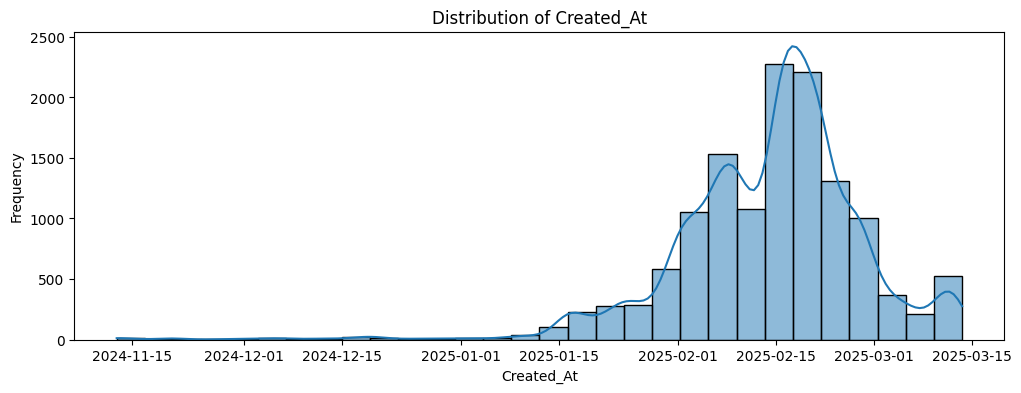

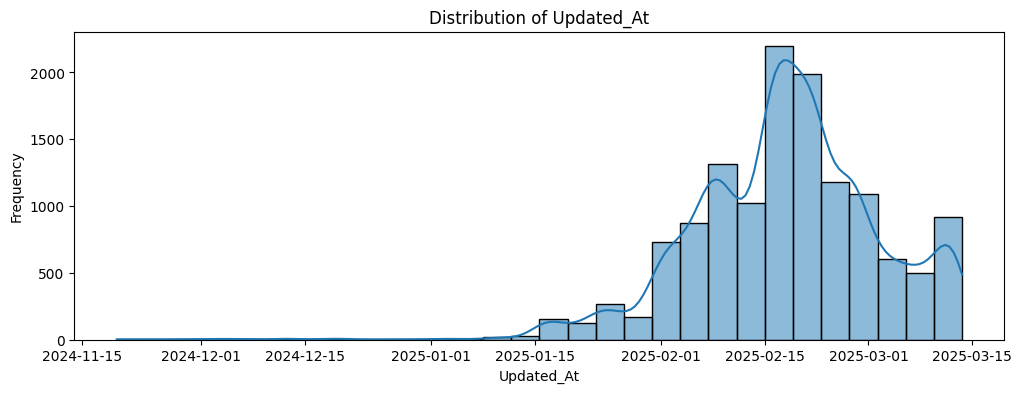

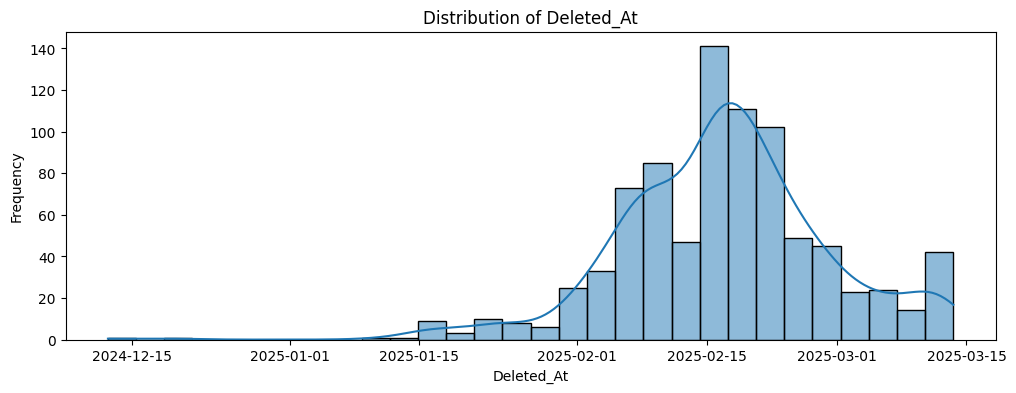

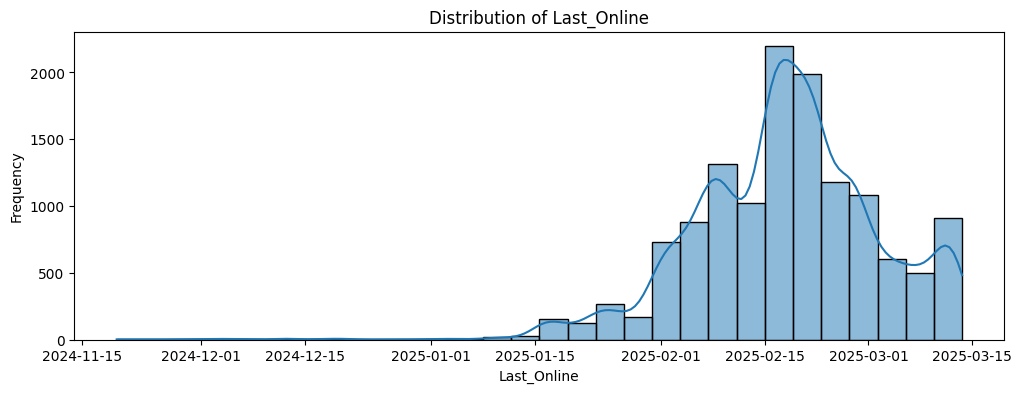

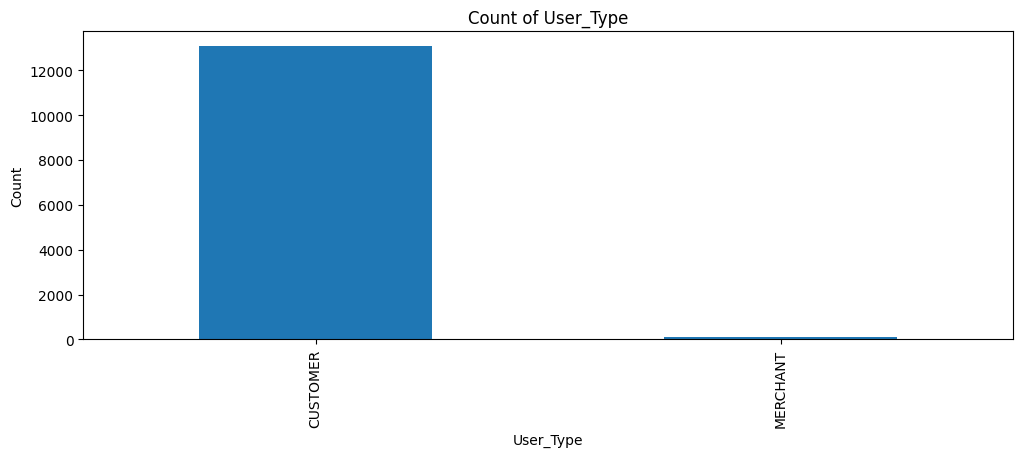

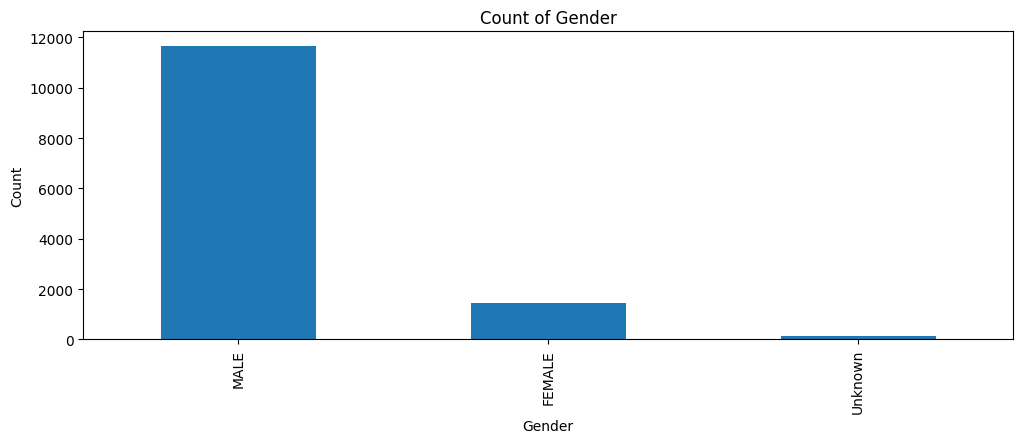

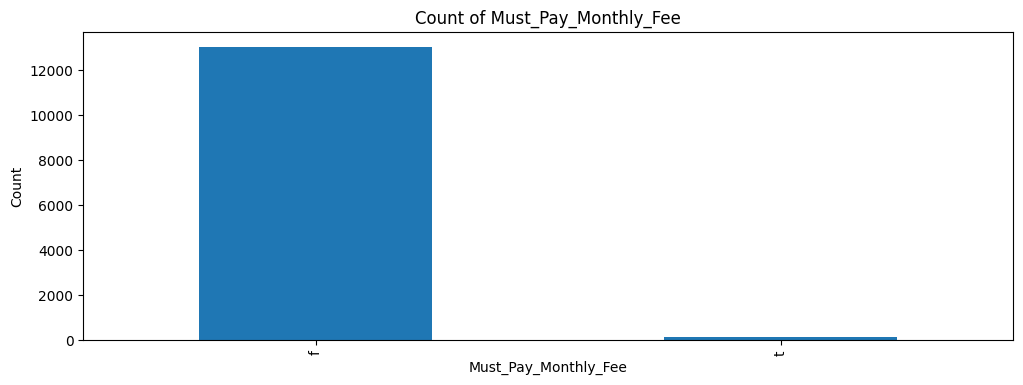

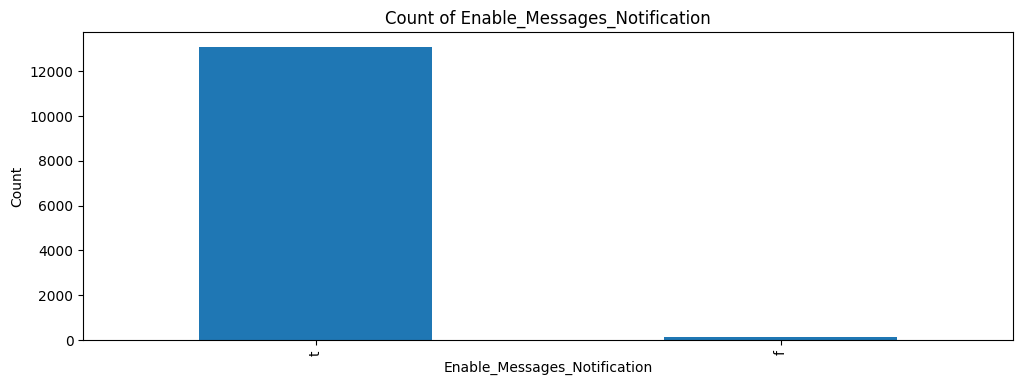

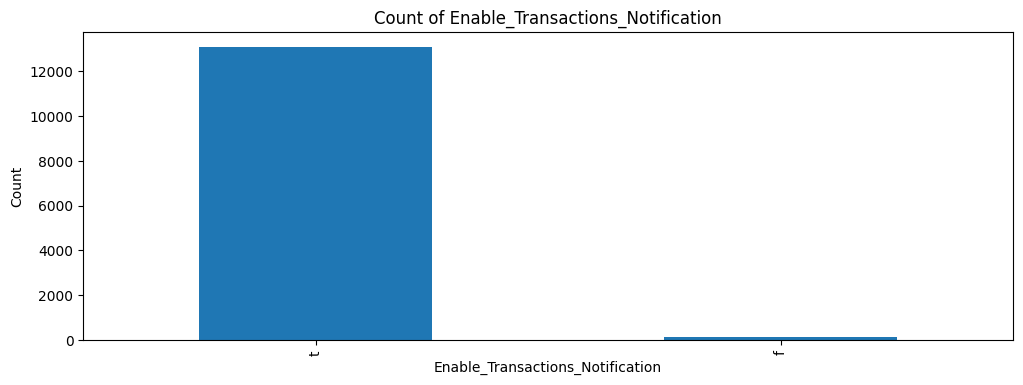

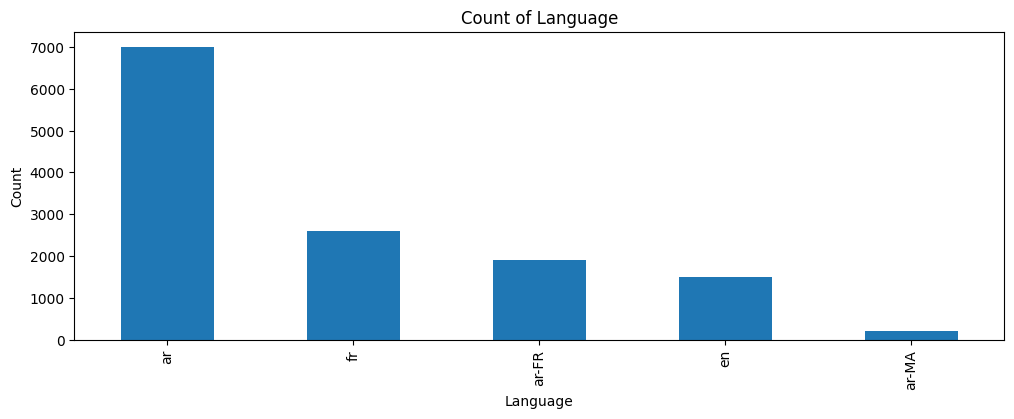

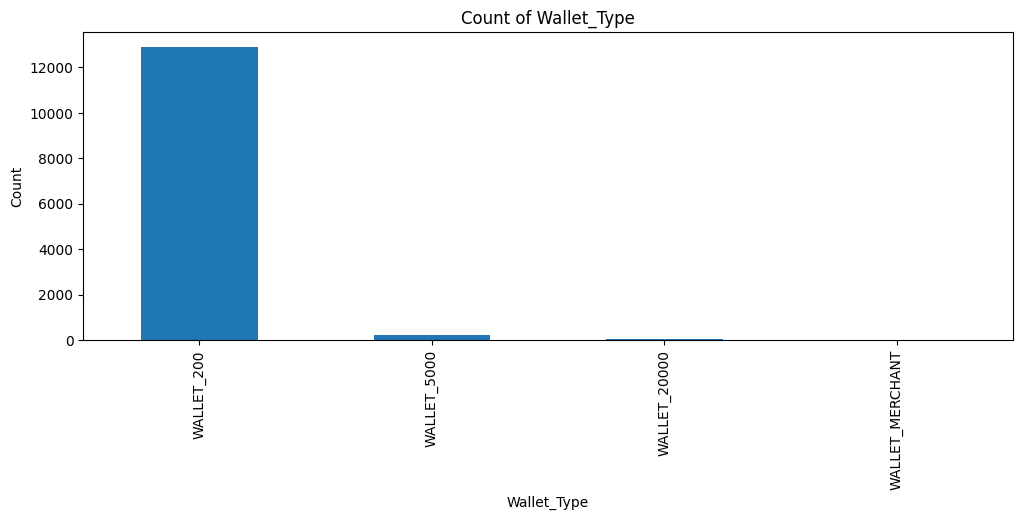

Text(0, 0.5, 'Count')

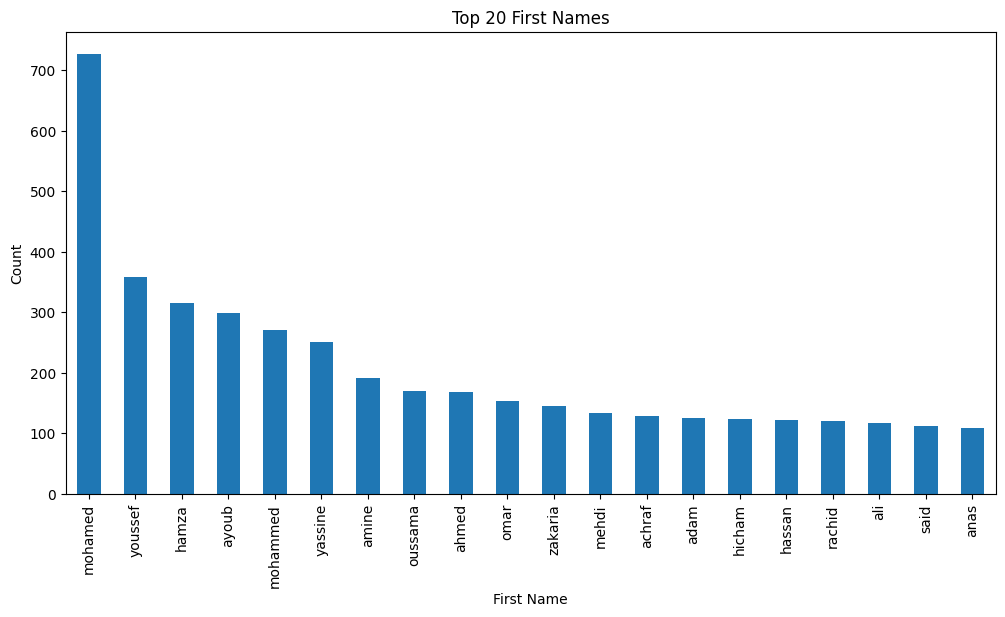

In [141]:
# Univariate analysis for numerical features in users_clean 
numerical_features = users_clean.select_dtypes(include=['int64', 'float64', 'datetime64[ns]']).columns
for feature in numerical_features:
    plt.figure(figsize=(12, 4))
    sns.histplot(users_clean[feature].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

# Univariate analysis for categorical features in users_clean
categorical_features = users_clean.select_dtypes(include=['object']).columns
categorical_features = categorical_features.drop(['User_Id','Avatar','First_Name'])  # Exclude 'User_Id', 'Avatar', and 'First_Name'
for feature in categorical_features:
    plt.figure(figsize=(12, 4))
    users_clean[feature].value_counts().plot(kind='bar')
    plt.title(f'Count of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.show()

# Visualizing the top 20 first names
top_20_names = users_clean['First_Name'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_20_names.plot(kind='bar')
plt.title('Top 20 First Names')
plt.xlabel('First Name')
plt.ylabel('Count')

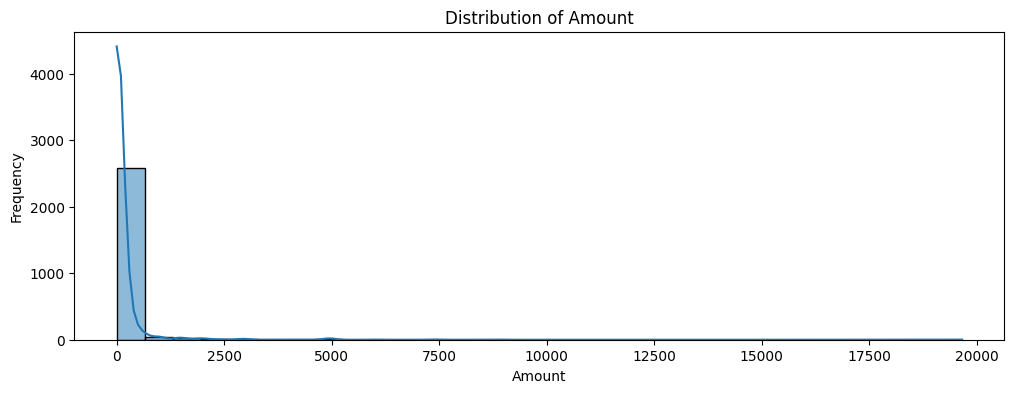

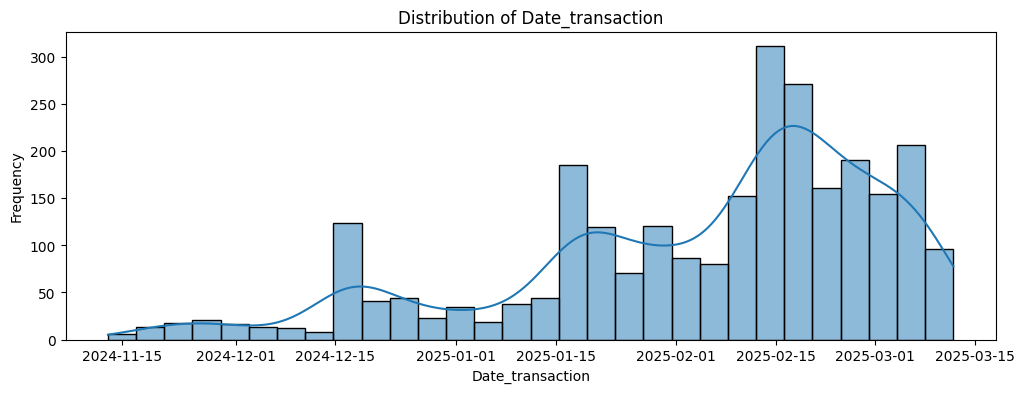

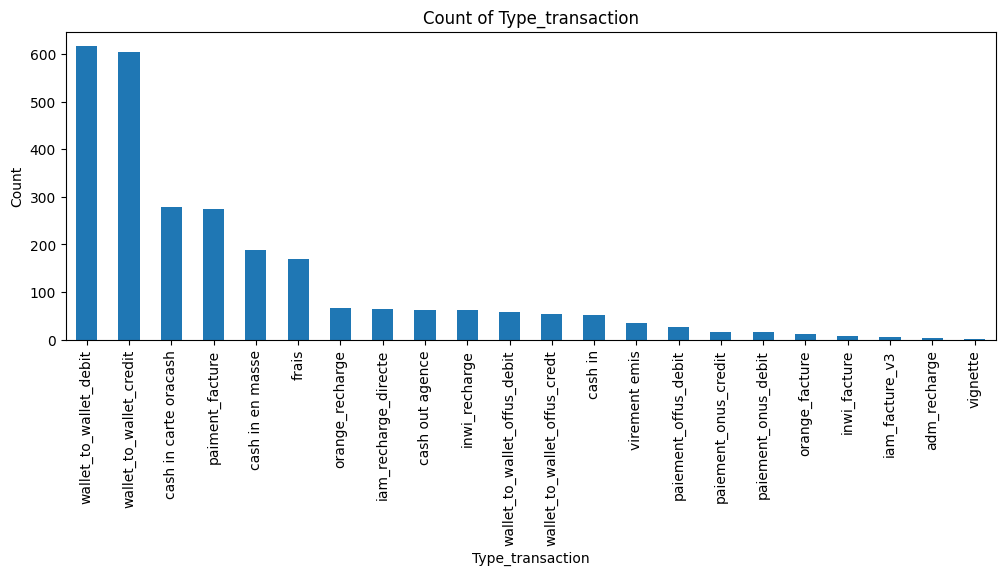

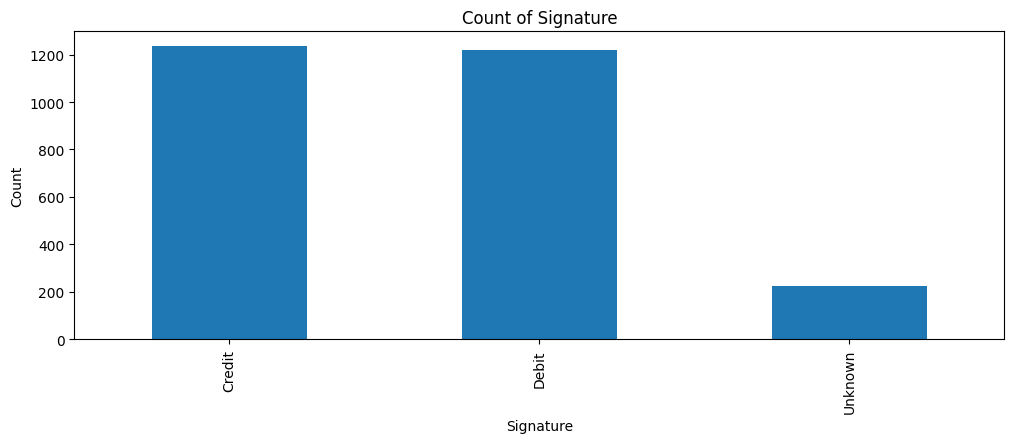

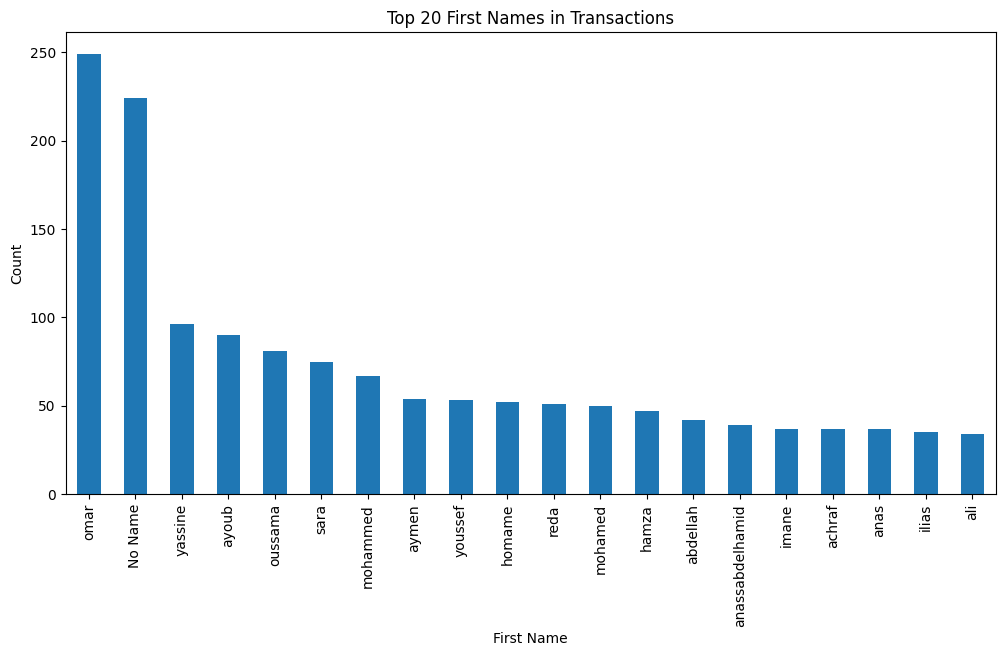

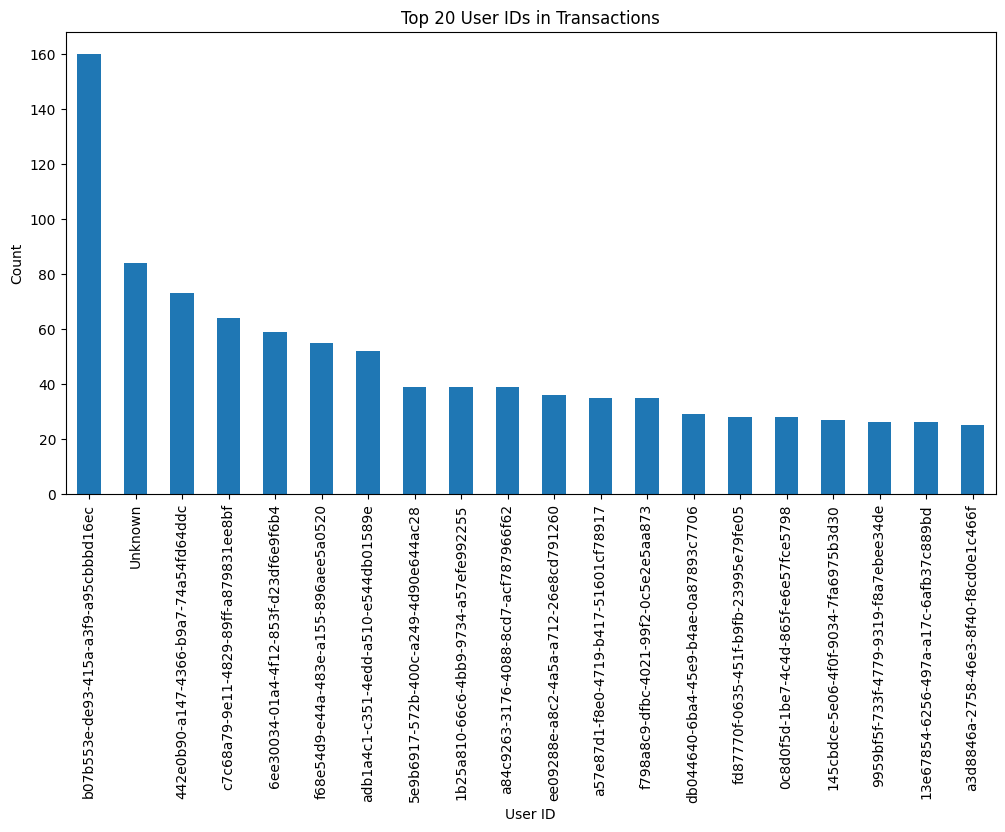

In [142]:
# Univariate analysis for numerical features in transactions
numerical_features = transactions_clean.select_dtypes(include=['int64', 'float64', 'datetime64[ns]']).columns
for feature in numerical_features:
    plt.figure(figsize=(12, 4))
    sns.histplot(transactions_clean[feature].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

# Univariate analysis for categorical features in transactions
categorical_features = transactions_clean.select_dtypes(include=['object']).columns
categorical_features = categorical_features.drop(['User_Id', 'First_Name', 'Time'])  # Exclude User_Id and First_Name
for feature in categorical_features:
    plt.figure(figsize=(12, 4))
    transactions_clean[feature].value_counts().plot(kind='bar')
    plt.title(f'Count of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    
    plt.show()

# Visualizing the top 20 first names
top_20_names = transactions_clean['First_Name'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_20_names.plot(kind='bar')
plt.title('Top 20 First Names in Transactions')
plt.xlabel('First Name')
plt.ylabel('Count')
plt.show()

# Visualizing the top 20 User IDs
top_20_ids = transactions_clean['User_Id'].value_counts().head(20)
plt.figure(figsize=(12, 6))
top_20_ids.plot(kind='bar')
plt.title('Top 20 User IDs in Transactions')
plt.xlabel('User ID')
plt.ylabel('Count')
plt.show()

## Feature Engineering :
Feature engineering is a critical step in the machine learning pipeline that involves transforming raw data into meaningful features to improve the performance of predictive models. In this project, new features are extracted from the `transactions` dataset, such as transaction counts, average transaction amounts, and activity periods, to merge this information with the `users` dataset. This integration enables a comprehensive view of user behavior and enhances the model's ability to predict churn. The process also includes encoding categorical variables, scaling numerical features, and creating new features through domain knowledge or mathematical transformations. By enhancing the quality and relevance of the input data, feature engineering helps to reduce noise, improve model interpretability, and optimize predictive accuracy.

In [143]:
import pandas as pd
import numpy as np
from datetime import timedelta
from scipy.stats import skew, kurtosis
import warnings
warnings.filterwarnings('ignore')

def engineer_features(users_clean, transactions_clean, current_date=pd.Timestamp('2025-05-20')):
    """
    Advanced feature engineering pipeline combining user and transaction data
    for churn prediction, with comprehensive time-based, behavioral, and statistical features.
    
    Parameters:
    -----------
    users_clean : pd.DataFrame
        Clean users dataset
    transactions_clean : pd.DataFrame
        Clean transactions dataset
    current_date : pd.Timestamp
        Reference date for time-based calculations
    
    Returns:
    --------
    pd.DataFrame
        Feature-rich dataframe ready for modeling
    """
    print("Starting advanced feature engineering pipeline...")
    start_shape = users_clean.shape
    
    # Make deep copies to avoid modification warnings
    users = users_clean.copy()
    transactions = transactions_clean.copy()
    
    # Debug: Check column names to ensure 'User_Id' exists in both dataframes
    print(f"Users columns: {users.columns.tolist()}")
    print(f"Transactions columns: {transactions.columns.tolist()}")
    
    # Ensure consistent column name for user ID
    # Check if "User_Id" exists in both DataFrames, otherwise look for alternatives
    user_id_col_users = 'User_Id' if 'User_Id' in users.columns else next((col for col in users.columns if col.lower() == 'user_id'), None)
    user_id_col_txn = 'User_Id' if 'User_Id' in transactions.columns else next((col for col in transactions.columns if col.lower() == 'user_id'), None)
    
    if not user_id_col_users or not user_id_col_txn:
        print("ERROR: Cannot find User_Id column in one or both DataFrames")
        print(f"Users DataFrame columns: {users.columns.tolist()}")
        print(f"Transactions DataFrame columns: {transactions.columns.tolist()}")
        raise ValueError("User_Id column not found")
        
    # Rename columns to ensure they match
    users = users.rename(columns={user_id_col_users: 'user_id'})
    transactions = transactions.rename(columns={user_id_col_txn: 'user_id'})
    
    LARGE_TIME_VALUE = 999999.0  # Used for undefined time gaps
    
    # ============================================================================
    # 1. TIME NORMALIZATION AND TRANSACTION PREPROCESSING
    # ============================================================================
    
    # Convert datetime columns if they aren't already
    for col in ['Created_At', 'Updated_At', 'Deleted_At', 'Last_Online']:
        if col in users.columns and users[col].dtype != 'datetime64[ns]':
            users[col] = pd.to_datetime(users[col])
    
    # Ensure transactions have proper datetime format
    if 'Time' in transactions.columns:
        transactions['Time'] = pd.to_timedelta(transactions['Time'].astype(str))
        
    if 'Date_transaction' in transactions.columns and 'Time' in transactions.columns:
        transactions['Transaction_Datetime'] = pd.to_datetime(transactions['Date_transaction']) + transactions['Time']
    elif 'Transaction_Datetime' not in transactions.columns:
        print("WARNING: Cannot create Transaction_Datetime. Using Date_transaction as fallback.")
        if 'Date_transaction' in transactions.columns:
            transactions['Transaction_Datetime'] = pd.to_datetime(transactions['Date_transaction'])
        else:
            print("ERROR: No transaction date column found")
            raise ValueError("No transaction date column")
    
    # Handle any remaining NaT values in transaction datetimes
    transactions = transactions.dropna(subset=['Transaction_Datetime'])
    
    # Sort transactions chronologically
    transactions = transactions.sort_values(by=['user_id', 'Transaction_Datetime'])
    
    # ============================================================================
    # 2. CORE USER TIMELINE FEATURES
    # ============================================================================
    
    # Key timeline features - using provided current date
    users['time_since_creation'] = (current_date - users['Created_At']).dt.total_seconds() / (24*3600)
    users['time_since_update'] = (current_date - users['Updated_At']).dt.total_seconds() / (24*3600) 
    users['time_since_last_online'] = (current_date - users['Last_Online']).dt.total_seconds() / (24*3600)
    
    # Fill NaN values in time_since columns with high values
    users['time_since_last_online'] = users['time_since_last_online'].fillna(LARGE_TIME_VALUE)
    
    # Activity spans (time between first and last activity of different types)
    users['account_duration'] = (current_date - users['Created_At']).dt.total_seconds() / (24*3600)
    users['activity_duration'] = (users['Last_Online'] - users['Created_At']).dt.total_seconds() / (24*3600)
    users['activity_duration'] = users['activity_duration'].fillna(0)
    
    # Recency indicators (binary flags)
    users['inactive_7d'] = (users['time_since_last_online'] > 7).astype(int)
    users['inactive_14d'] = (users['time_since_last_online'] > 14).astype(int)
    users['inactive_30d'] = (users['time_since_last_online'] > 30).astype(int)
    users['inactive_90d'] = (users['time_since_last_online'] > 90).astype(int)
    
    # ============================================================================
    # 3. TRANSACTION COUNTS BY TYPE AND SIGNATURE
    # ============================================================================
    
    # General transaction counts - with robust error handling
    try:
        print("Creating transaction counts...")
        
        # Create a copy of the groupby result to inspect
        txn_counts_df = transactions.groupby('user_id').size().reset_index(name='num_transactions')
        
        # Try merging with explicit column naming
        users = users.merge(
            txn_counts_df[['user_id', 'num_transactions']], 
            on='user_id', 
            how='left'
        )
        
        # Fill NaN values
        users['num_transactions'] = users['num_transactions'].fillna(0).astype(int)
        print(f"Successfully created num_transactions. Total transactions: {users['num_transactions'].sum()}")
            
    except Exception as e:
        print(f"ERROR in transaction count processing: {str(e)}")
        # Create a fallback column
        users['num_transactions'] = 0
        print("Created fallback num_transactions column with all zeros")

    # Transaction signature counts (Debit/Credit) - with robust error handling
    if 'Signature' in transactions.columns:
        # Get unique signature values
        signature_values = transactions['Signature'].unique()
        print(f"Found signature values: {signature_values}")
        
        # Process each signature value that exists
        for signature in ['Debit', 'Credit']:
            # Check if this signature exists in the data
            if signature in signature_values:
                try:
                    # Create column name
                    col_name = f"num_{signature.lower()}_transactions"
                    
                    # Get transactions with this signature
                    sig_txns = transactions[transactions['Signature'] == signature]
                    
                    # Group and count
                    sig_count = sig_txns.groupby('user_id').size().reset_index(name=col_name)
                    
                    # Merge with main dataframe
                    users = users.merge(sig_count, on='user_id', how='left')
                    
                    # Fill NaN values
                    users[col_name] = users[col_name].fillna(0).astype(int)
                    print(f"Created {col_name} column with {users[col_name].sum()} transactions")
                    
                except Exception as e:
                    print(f"Error creating {signature} transaction counts: {str(e)}")
                    # Create fallback column
                    users[f"num_{signature.lower()}_transactions"] = 0
            else:
                print(f"Signature '{signature}' not found in data, creating zero-filled column")
                users[f"num_{signature.lower()}_transactions"] = 0
    else:
        print("No 'Signature' column found in transactions, creating zero-filled columns")
        users["num_debit_transactions"] = 0
        users["num_credit_transactions"] = 0
    
    # Transaction type counts - with robust error handling
    if 'Type_transaction' in transactions.columns:
        try:
            # Get unique transaction types
            txn_types = transactions['Type_transaction'].unique()
            print(f"Found {len(txn_types)} transaction types")
            
            # For each transaction type, create a count column
            for txn_type in txn_types:
                col_name = f"num_{'_'.join(str(txn_type).lower().split())}"
                
                # Count transactions of this type
                type_count = transactions[transactions['Type_transaction'] == txn_type].groupby('user_id').size().reset_index(name=col_name)
                
                # Merge with main dataframe
                users = users.merge(type_count, on='user_id', how='left')
                
                # Fill NaN values
                users[col_name] = users[col_name].fillna(0).astype(int)
                
            print("Successfully created transaction type count columns")
                
        except Exception as e:
            print(f"Error creating transaction type counts: {str(e)}")
    
    # ============================================================================
    # 4. TRANSACTION AMOUNT FEATURES
    # ============================================================================
    
    # Standard amount metrics - with robust error handling
    if 'Amount' in transactions.columns:
        try:
            # Create amount aggregations
            txn_amounts = transactions.groupby('user_id')['Amount'].agg([
                ('avg_transaction_amount', 'mean'),
                ('median_transaction_amount', 'median'),
                ('max_transaction_amount', 'max'),
                ('min_transaction_amount', 'min'),
                ('std_transaction_amount', 'std'),
                ('total_transaction_amount', 'sum'),
            ]).reset_index()
            
            # Merge with main dataframe
            users = users.merge(txn_amounts, on='user_id', how='left')
            
            # Fill NaN values
            amount_cols = ['avg_transaction_amount', 'median_transaction_amount', 
                          'max_transaction_amount', 'min_transaction_amount', 
                          'total_transaction_amount', 'std_transaction_amount']
            users[amount_cols] = users[amount_cols].fillna(0)
            
            print("Successfully created transaction amount metrics")
            
            # Amount aggregations by signature
            if 'Signature' in transactions.columns:
                for signature in ['Debit', 'Credit']:
                    if signature in transactions['Signature'].unique():
                        try:
                            # Create aggregations for this signature
                            sig_amounts = (transactions[transactions['Signature'] == signature]
                                          .groupby('user_id')['Amount']
                                          .agg(['mean', 'sum'])
                                          .reset_index())
                            sig_amounts.columns = ['user_id', 
                                                  f'avg_{signature.lower()}_amount', 
                                                  f'total_{signature.lower()}_amount']
                            
                            # Merge with main dataframe
                            users = users.merge(sig_amounts, on='user_id', how='left')
                            
                            # Fill NaN values
                            users[f'avg_{signature.lower()}_amount'] = users[f'avg_{signature.lower()}_amount'].fillna(0)
                            users[f'total_{signature.lower()}_amount'] = users[f'total_{signature.lower()}_amount'].fillna(0)
                            
                        except Exception as e:
                            print(f"Error creating {signature} amount metrics: {str(e)}")
                            # Create fallback columns
                            users[f'avg_{signature.lower()}_amount'] = 0
                            users[f'total_{signature.lower()}_amount'] = 0
                    else:
                        # Create zero-filled columns
                        users[f'avg_{signature.lower()}_amount'] = 0
                        users[f'total_{signature.lower()}_amount'] = 0
            
        except Exception as e:
            print(f"Error creating transaction amount metrics: {str(e)}")
            # Create fallback columns
            basic_amount_cols = ['avg_transaction_amount', 'median_transaction_amount', 
                               'max_transaction_amount', 'min_transaction_amount', 
                               'total_transaction_amount', 'std_transaction_amount']
            for col in basic_amount_cols:
                users[col] = 0
    
    # Net flow calculations - with safety checks
    if all(col in users.columns for col in ['total_credit_amount', 'total_debit_amount']):
        users['net_money_flow'] = users['total_credit_amount'] - users['total_debit_amount']
        users['net_flow_per_day'] = users['net_money_flow'] / users['account_duration'].clip(1)
        users['is_net_positive'] = (users['net_money_flow'] > 0).astype(int)
    else:
        # Create fallback columns
        users['net_money_flow'] = 0
        users['net_flow_per_day'] = 0
        users['is_net_positive'] = 0
    
    # ============================================================================
    # 5. TRANSACTION FREQUENCY AND VELOCITY FEATURES
    # ============================================================================
    
    # Transaction timing features - with robust error handling
    try:
        txn_timing = transactions.groupby('user_id')['Transaction_Datetime'].agg([
            ('first_transaction_date', 'min'),
            ('last_transaction_date', 'max'),
        ]).reset_index()
        
        users = users.merge(txn_timing, on='user_id', how='left')
        
        # Handle users with no transactions
        users['first_transaction_date'] = users['first_transaction_date'].fillna(users['Created_At'])
        users['last_transaction_date'] = users['last_transaction_date'].fillna(users['Created_At'])
        
        print("Successfully created transaction timing features")
        
    except Exception as e:
        print(f"Error creating transaction timing features: {str(e)}")
        # Create fallback columns
        users['first_transaction_date'] = users['Created_At']
        users['last_transaction_date'] = users['Created_At']
    
    # Time from creation to first transaction (activation delay)
    users['time_to_first_transaction'] = (users['first_transaction_date'] - users['Created_At']).dt.total_seconds() / (24*3600)
    users['time_to_first_transaction'] = users['time_to_first_transaction'].clip(lower=0)  # Ensure non-negative
    
    # Time since last transaction (recency)
    users['time_since_last_transaction'] = (current_date - users['last_transaction_date']).dt.total_seconds() / (24*3600)
    
    # Calculate transaction frequency metrics
    users['transaction_activity_period'] = (users['last_transaction_date'] - users['first_transaction_date']).dt.total_seconds() / (24*3600)
    users['transaction_activity_period'] = users['transaction_activity_period'].clip(lower=0.1)  # Avoid division by zero
    
    # Transactions per day (over different periods)
    if 'num_transactions' in users.columns:
        users['txn_per_account_day'] = users['num_transactions'] / users['account_duration'].clip(lower=1)
        users['txn_per_active_day'] = users['num_transactions'] / users['transaction_activity_period'].clip(lower=1)
    else:
        users['txn_per_account_day'] = 0
        users['txn_per_active_day'] = 0
    
    # Transaction time difference statistics - with robust error handling
    try:
        transactions['time_since_previous_txn'] = transactions.groupby('user_id')['Transaction_Datetime'].diff().dt.total_seconds() / (24*3600)
        
        txn_diffs = transactions.groupby('user_id')['time_since_previous_txn'].agg([
            ('min_time_between_txn', 'min'),
            ('max_time_between_txn', 'max'),
            ('avg_time_between_txn', 'mean'),
            ('median_time_between_txn', 'median'),
            ('std_time_between_txn', 'std'),
        ]).reset_index()
        
        users = users.merge(txn_diffs, on='user_id', how='left')
        
        # Handle NaNs in time difference metrics
        time_diff_cols = ['min_time_between_txn', 'max_time_between_txn', 
                         'avg_time_between_txn', 'median_time_between_txn', 'std_time_between_txn']
        users[time_diff_cols] = users[time_diff_cols].fillna(LARGE_TIME_VALUE)
        users['std_time_between_txn'] = users['std_time_between_txn'].fillna(0)
        
        print("Successfully created transaction time difference statistics")
        
    except Exception as e:
        print(f"Error creating transaction time difference statistics: {str(e)}")
        # Create fallback columns
        time_diff_cols = ['min_time_between_txn', 'max_time_between_txn', 
                         'avg_time_between_txn', 'median_time_between_txn', 'std_time_between_txn']
        for col in time_diff_cols:
            users[col] = LARGE_TIME_VALUE if col != 'std_time_between_txn' else 0
    
    # ============================================================================
    # 6. RECENT TRANSACTION BEHAVIOR (LAST 30/90 DAYS)
    # ============================================================================
    
    # Last 30 days transaction behavior - with robust error handling
    try:
        cutoff_30d = current_date - timedelta(days=30)
        last_30d_txns = transactions[transactions['Transaction_Datetime'] >= cutoff_30d]
        
        # Count of transactions in last 30 days
        if not last_30d_txns.empty:
            last_30d_counts = last_30d_txns.groupby('user_id').size().reset_index(name='txn_count_last_30d')
            users = users.merge(last_30d_counts, on='user_id', how='left')
        else:
            # No transactions in last 30 days
            users['txn_count_last_30d'] = 0
            
        users['txn_count_last_30d'] = users['txn_count_last_30d'].fillna(0).astype(int)
        
        # Amount metrics for last 30 days
        if 'Amount' in last_30d_txns.columns and not last_30d_txns.empty:
            last_30d_amounts = last_30d_txns.groupby('user_id')['Amount'].agg('sum').reset_index(name='total_amount_last_30d')
            users = users.merge(last_30d_amounts, on='user_id', how='left')
            users['total_amount_last_30d'] = users['total_amount_last_30d'].fillna(0)
        else:
            users['total_amount_last_30d'] = 0
        
        print("Successfully created last 30 days transaction features")
            
    except Exception as e:
        print(f"Error creating last 30 days transaction features: {str(e)}")
        # Create fallback columns
        users['txn_count_last_30d'] = 0
        users['total_amount_last_30d'] = 0
    
    # Similarly for 90 days - with robust error handling
    try:
        cutoff_90d = current_date - timedelta(days=90)
        last_90d_txns = transactions[transactions['Transaction_Datetime'] >= cutoff_90d]
        
        # Count of transactions in last 90 days
        if not last_90d_txns.empty:
            last_90d_counts = last_90d_txns.groupby('user_id').size().reset_index(name='txn_count_last_90d')
            users = users.merge(last_90d_counts, on='user_id', how='left')
        else:
            # No transactions in last 90 days
            users['txn_count_last_90d'] = 0
            
        users['txn_count_last_90d'] = users['txn_count_last_90d'].fillna(0).astype(int)
        
        # Amount metrics for last 90 days
        if 'Amount' in last_90d_txns.columns and not last_90d_txns.empty:
            last_90d_amounts = last_90d_txns.groupby('user_id')['Amount'].agg('sum').reset_index(name='total_amount_last_90d')
            users = users.merge(last_90d_amounts, on='user_id', how='left')
            users['total_amount_last_90d'] = users['total_amount_last_90d'].fillna(0)
        else:
            users['total_amount_last_90d'] = 0
        
        print("Successfully created last 90 days transaction features")
            
    except Exception as e:
        print(f"Error creating last 90 days transaction features: {str(e)}")
        # Create fallback columns
        users['txn_count_last_90d'] = 0
        users['total_amount_last_90d'] = 0
    
    # ============================================================================
    # 7. TRANSACTION PATTERNS AND DIVERSITY METRICS
    # ============================================================================
    
    # Transaction type diversity - with robust error handling
    try:
        # Check for necessary columns
        num_cols = [col for col in users.columns if col.startswith('num_')]
        txn_type_cols = [col for col in num_cols if col not in ['num_transactions', 'num_debit_transactions', 'num_credit_transactions']]
        
        if txn_type_cols:
            users['txn_type_diversity'] = (users[txn_type_cols] > 0).sum(axis=1)
            users['txn_type_diversity_ratio'] = users['txn_type_diversity'] / max(len(txn_type_cols), 1)
            
            # Concentration in top transaction type
            users['top_txn_type_concentration'] = users[txn_type_cols].max(axis=1) / users['num_transactions'].clip(lower=1)
            
            print(f"Successfully created transaction diversity metrics with {len(txn_type_cols)} transaction types")
        else:
            # No transaction type columns
            users['txn_type_diversity'] = 0
            users['txn_type_diversity_ratio'] = 0
            users['top_txn_type_concentration'] = 0
            
            print("No transaction type columns found, created zero-filled diversity metrics")
        
    except Exception as e:
        print(f"Error creating transaction diversity metrics: {str(e)}")
        # Create fallback columns
        users['txn_type_diversity'] = 0
        users['txn_type_diversity_ratio'] = 0
        users['top_txn_type_concentration'] = 0
    
    # Credit to debit ratio - with safety checks
    if 'num_credit_transactions' in users.columns and 'num_debit_transactions' in users.columns:
        users['credit_to_debit_ratio'] = users['num_credit_transactions'] / users['num_debit_transactions'].clip(lower=1)
    else:
        users['credit_to_debit_ratio'] = 0
    
    if 'total_credit_amount' in users.columns and 'total_debit_amount' in users.columns:
        users['credit_to_debit_amount_ratio'] = users['total_credit_amount'] / users['total_debit_amount'].clip(lower=1)
    else:
        users['credit_to_debit_amount_ratio'] = 0
    
    # Transaction consistency - with safety checks
    if 'std_time_between_txn' in users.columns and 'avg_time_between_txn' in users.columns:
        users['txn_consistency'] = 1 - (users['std_time_between_txn'] / users['avg_time_between_txn'].clip(lower=1)).clip(upper=1)
        users['txn_consistency'] = users['txn_consistency'].fillna(0)
    else:
        users['txn_consistency'] = 0
    
    # ============================================================================
    # 8. USER LIFECYCLE AND ENGAGEMENT SEGMENTS
    # ============================================================================
    
    # User lifecycle segments
    users['is_new_user'] = (users['time_since_creation'] <= 30).astype(int)
    users['is_recent_user'] = ((users['time_since_creation'] > 30) & 
                             (users['time_since_creation'] <= 90)).astype(int)
    users['is_established_user'] = ((users['time_since_creation'] > 90) & 
                                  (users['time_since_creation'] <= 365)).astype(int)
    users['is_mature_user'] = (users['time_since_creation'] > 365).astype(int)
    
    # Activity segments - with safety checks
    if 'txn_per_account_day' in users.columns:
        try:
            users['is_very_active'] = (users['txn_per_account_day'] > 
                                      users['txn_per_account_day'].quantile(0.75)).astype(int)
            users['is_active'] = ((users['txn_per_account_day'] > users['txn_per_account_day'].quantile(0.5)) & 
                                 (users['txn_per_account_day'] <= users['txn_per_account_day'].quantile(0.75))).astype(int)
            users['is_casual_user'] = ((users['txn_per_account_day'] > users['txn_per_account_day'].quantile(0.25)) &
                                     (users['txn_per_account_day'] <= users['txn_per_account_day'].quantile(0.5))).astype(int)
            users['is_rare_user'] = (users['txn_per_account_day'] <= 
                                   users['txn_per_account_day'].quantile(0.25)).astype(int)
        except Exception as e:
            print(f"Error creating activity segments: {str(e)}")
            # Create fallback columns with even distribution
            users['is_very_active'] = (users['num_transactions'] > 0).astype(int) * 0.25
            users['is_active'] = (users['num_transactions'] > 0).astype(int) * 0.25
            users['is_casual_user'] = (users['num_transactions'] > 0).astype(int) * 0.25
            users['is_rare_user'] = (users['num_transactions'] > 0).astype(int) * 0.25
    else:
        # Create fallback columns
        users['is_very_active'] = 0
        users['is_active'] = 0
        users['is_casual_user'] = 0
        users['is_rare_user'] = 1  # Default to rare user
    
    # ============================================================================
    # 9. DORMANCY AND ENGAGEMENT DECAY INDICATORS
    # ============================================================================
    
    # Post-transaction dormancy (time since last transaction to last online)
    users['post_txn_dormancy'] = (users['Last_Online'] - users['last_transaction_date']).dt.total_seconds() / (24*3600)
    users['post_txn_dormancy'] = users['post_txn_dormancy'].clip(lower=0)  # Ensure non-negative
    
    # Calculate dormancy ratio
    users['dormancy_ratio'] = users['post_txn_dormancy'] / users['account_duration'].clip(lower=1)
    
    # Engagement decay
    users['activity_recency_ratio'] = users['time_since_last_online'] / users['time_since_creation'].clip(lower=1)
    users['txn_recency_ratio'] = users['time_since_last_transaction'] / users['time_since_creation'].clip(lower=1)
    
    # Engagement flags - with safety checks
    if 'txn_count_last_30d' in users.columns:
        users['engagement_decay_30d'] = ((users['txn_count_last_30d'] == 0) & 
                                       (users['time_since_creation'] > 30)).astype(int)
    else:
        users['engagement_decay_30d'] = 0
    
    if 'txn_count_last_90d' in users.columns:
        users['engagement_decay_90d'] = ((users['txn_count_last_90d'] == 0) & 
                                       (users['time_since_creation'] > 90)).astype(int)
    else:
        users['engagement_decay_90d'] = 0
    
    # High-risk dormancy flags
    users['high_risk_dormancy'] = ((users['time_since_last_transaction'] > 60) & 
                                 (users['time_since_last_online'] > 30) &
                                 (users['time_since_creation'] > 90)).astype(int)
    
    # ============================================================================
    # 10. NOTIFICATION AND PREFERENCE-BASED FEATURES
    # ============================================================================
    
    # Create numerical flags from boolean columns
    bool_cols = ['Must_Pay_Monthly_Fee', 'Enable_Messages_Notification', 'Enable_Transactions_Notification']
    for col in bool_cols:
        if col in users.columns:
            users[col] = users[col].map({
                True: 1, 'true': 1, 't': 1, 
                False: 0, 'false': 0, 'f': 0
            }).fillna(0).astype(int)
    
    # Interaction between notifications and activity
    if all(col in users.columns for col in ['Enable_Transactions_Notification', 'inactive_30d']):
        users['inactive_with_notifications'] = ((users['Enable_Transactions_Notification'] == 1) & 
                                             (users['inactive_30d'] == 1)).astype(int)
        users['inactive_without_notifications'] = ((users['Enable_Transactions_Notification'] == 0) & 
                                                (users['inactive_30d'] == 1)).astype(int)
    else:
        users['inactive_with_notifications'] = 0
        users['inactive_without_notifications'] = 0
    
    # ============================================================================
    # 11. PROCESS CATEGORICAL VARIABLES
    # ============================================================================
    
    # User Type
    if 'User_Type' in users.columns:
        try:
            user_type_dummies = pd.get_dummies(users['User_Type'], prefix='User_Type', dummy_na=True)
            users = pd.concat([users, user_type_dummies], axis=1)
        except Exception as e:
            print(f"Error creating User_Type dummies: {str(e)}")
    
    # Gender
    if 'Gender' in users.columns:
        try:
            gender_dummies = pd.get_dummies(users['Gender'], prefix='Gender', dummy_na=True)
            users = pd.concat([users, gender_dummies], axis=1)
        except Exception as e:
            print(f"Error creating Gender dummies: {str(e)}")
    
    # Language
    if 'Language' in users.columns:
        try:
            language_dummies = pd.get_dummies(users['Language'], prefix='Language', dummy_na=True)
            users = pd.concat([users, language_dummies], axis=1)
        except Exception as e:
            print(f"Error creating Language dummies: {str(e)}")
    
    # Wallet Type
    if 'Wallet_Type' in users.columns:
        try:
            wallet_dummies = pd.get_dummies(users['Wallet_Type'], prefix='Wallet_Type', dummy_na=True)
            users = pd.concat([users, wallet_dummies], axis=1)
        except Exception as e:
            print(f"Error creating Wallet_Type dummies: {str(e)}")
    
    # Avatar processing - extract class from JSON if needed
    if 'Avatar' in users.columns:
        # Check if Avatar is string (JSON)
        if users['Avatar'].dtype == 'object':
            try:
                # Try simple string pattern matching for avatar class
                users['Avatar_Class'] = users['Avatar'].str.extract(r'/avatars/([^/]+)/').fillna('unknown')
                
                # Create dummy variables
                avatar_dummies = pd.get_dummies(users['Avatar_Class'], prefix='Avatar_Class', dummy_na=True)
                users = pd.concat([users, avatar_dummies], axis=1)
            except Exception as e:
                print(f"Error processing Avatar column: {str(e)}")
    
    # ============================================================================
    # 12. ADVANCED STATISTICAL TRANSFORMATIONS
    # ============================================================================
    
    # Log transformations for skewed continuous variables
    log_cols = [
        'time_since_creation', 'time_since_update', 'time_since_last_online', 
        'time_since_last_transaction', 'avg_transaction_amount', 
        'total_transaction_amount', 'account_duration'
    ]
    
    for col in log_cols:
        if col in users.columns:
            users[f'{col}_log'] = np.log1p(users[col])
    
    # Square root transformations (alternative to log)
    sqrt_cols = [
        'time_since_last_transaction', 'avg_time_between_txn', 'txn_per_account_day'
    ]
    
    for col in sqrt_cols:
        if col in users.columns:
            users[f'{col}_sqrt'] = np.sqrt(users[col])
    
    # Ratios of key metrics - with safety checks
    if all(col in users.columns for col in ['net_money_flow', 'num_transactions']):
        users['money_flow_per_txn'] = users['net_money_flow'] / users['num_transactions'].clip(lower=1)
    else:
        users['money_flow_per_txn'] = 0
    
    if all(col in users.columns for col in ['total_transaction_amount', 'num_transactions']):
        users['efficiency_ratio'] = users['total_transaction_amount'] / users['num_transactions'].clip(lower=1)
    else:
        users['efficiency_ratio'] = 0
    
    # Z-score normalizations for key metrics
    zscore_cols = [
        'time_since_last_transaction', 'activity_duration', 'txn_per_account_day'
    ]
    
    for col in zscore_cols:
        if col in users.columns:
            try:
                mean = users[col].mean()
                std = users[col].std()
                if std > 0:
                    users[f'{col}_zscore'] = (users[col] - mean) / std
                else:
                    users[f'{col}_zscore'] = 0
            except Exception as e:
                print(f"Error creating z-score for {col}: {str(e)}")
                users[f'{col}_zscore'] = 0
    
    # ============================================================================
    # 13. INTERACTION FEATURES
    # ============================================================================
    
    # Lifecycle-specific transaction behavior - with safety checks
    if all(col in users.columns for col in ['is_new_user', 'txn_per_account_day']):
        users['new_user_x_txn_frequency'] = users['is_new_user'] * users['txn_per_account_day']
    else:
        users['new_user_x_txn_frequency'] = 0
    
    if all(col in users.columns for col in ['is_mature_user', 'engagement_decay_90d']):
        users['mature_user_x_decay'] = users['is_mature_user'] * users['engagement_decay_90d']
    else:
        users['mature_user_x_decay'] = 0
    
    # High value and risk interactions - with safety checks
    if 'total_transaction_amount' in users.columns:
        try:
            users['high_value_user'] = (users['total_transaction_amount'] > 
                                      users['total_transaction_amount'].quantile(0.75)).astype(int)
            
            if 'inactive_30d' in users.columns:
                users['high_value_inactive'] = users['high_value_user'] * users['inactive_30d']
            else:
                users['high_value_inactive'] = 0
        except Exception as e:
            print(f"Error creating high value user features: {str(e)}")
            users['high_value_user'] = 0
            users['high_value_inactive'] = 0
    else:
        users['high_value_user'] = 0
        users['high_value_inactive'] = 0
    
    # Notification and activity interactions - with safety checks
    notif_cols = [
        'Enable_Messages_Notification', 'Enable_Transactions_Notification'
    ]
    
    for col in notif_cols:
        if col in users.columns:
            if 'txn_per_account_day' in users.columns:
                users[f'{col}_x_activity'] = users[col] * users['txn_per_account_day']
            else:
                users[f'{col}_x_activity'] = 0
                
            if 'time_since_last_online' in users.columns:
                users[f'{col}_x_dormancy'] = users[col] * (users['time_since_last_online'] > 30).astype(int)
            else:
                users[f'{col}_x_dormancy'] = 0
    
    # ============================================================================
    # 14. CHURN INDICATOR AND TIMING
    # ============================================================================
    
    # Ensure churn target is created
    users['churn_target'] = users['Deleted_At'].notna().astype(int)
    
    # For churned users, calculate time metrics
    try:
        users['time_to_churn'] = np.where(
            users['churn_target'] == 1,
            (users['Deleted_At'] - users['Created_At']).dt.total_seconds() / (24*3600),
            np.nan
        )
        
        users['updated_before_churn'] = np.where(
            users['churn_target'] == 1,
            (users['Deleted_At'] - users['Updated_At']).dt.total_seconds() / (24*3600),
            np.nan
        )
    except Exception as e:
        print(f"Error creating churn timing features: {str(e)}")
        users['time_to_churn'] = np.nan
        users['updated_before_churn'] = np.nan
    
    # ============================================================================
    # 15. FINAL CLEANUP
    # ============================================================================
    
    # Drop columns we shouldn't use in modeling
    drop_columns = [
        'Created_At', 'Updated_At', 'Deleted_At', 'Last_Online',
        'first_transaction_date', 'last_transaction_date',
        'First_Name'  # This is likely not predictive
    ]
    
    # Only drop columns that exist
    drop_columns = [col for col in drop_columns if col in users.columns]
    
    # Drop any JSON columns that were converted to dummies
    if 'Avatar' in users.columns and 'Avatar_Class' in users.columns:
        drop_columns.append('Avatar')
    
    # Remove original categorical columns if we've created dummies
    for col in ['User_Type', 'Gender', 'Language', 'Wallet_Type', 'Avatar_Class']:
        if col in users.columns and any(users.columns.str.startswith(f'{col}_')):
            drop_columns.append(col)
    
    # Restore original User_Id if needed
    if user_id_col_users != 'user_id':
        users = users.rename(columns={'user_id': user_id_col_users})
    
    # Actually drop the columns
    users = users.drop(columns=drop_columns, errors='ignore')
    
    # Fill any remaining NaN values
    users = users.fillna(0)
    
    # Report on feature engineering results
    end_shape = users.shape
    print(f"Feature engineering complete!")
    print(f"Started with {start_shape[1]} features, ended with {end_shape[1]} features.")
    print(f"Added {end_shape[1] - start_shape[1]} new engineered features.")
    
    return users

In [144]:
current_date = pd.Timestamp('2025-05-20')

# Apply the enhanced feature engineering
data = engineer_features(users_clean, transactions_clean, current_date)


Starting advanced feature engineering pipeline...
Users columns: ['User_Id', 'User_Type', 'Gender', 'Created_At', 'Updated_At', 'Deleted_At', 'First_Name', 'Last_Online', 'Avatar', 'Must_Pay_Monthly_Fee', 'Enable_Messages_Notification', 'Enable_Transactions_Notification', 'Language', 'Wallet_Type']
Transactions columns: ['User_Id', 'Amount', 'Date_transaction', 'Time', 'Type_transaction', 'Signature', 'First_Name']
Creating transaction counts...
Successfully created num_transactions. Total transactions: 2594
Found signature values: ['Credit' 'Debit' 'Unknown']
Created num_debit_transactions column with 1202 transactions
Created num_credit_transactions column with 1181 transactions
Found 22 transaction types


Successfully created transaction type count columns
Successfully created transaction amount metrics
Successfully created transaction timing features
Successfully created transaction time difference statistics
Successfully created last 30 days transaction features
Successfully created last 90 days transaction features
Successfully created transaction diversity metrics with 22 transaction types
Feature engineering complete!
Started with 14 features, ended with 136 features.
Added 122 new engineered features.


In [145]:
def encode_categorical_features(df, encoding_method='auto', cardinality_threshold=10):
    """
    Encode categorical features using either one-hot encoding, label encoding, or a hybrid approach.
    
    Parameters:
    -----------
    df : pd.DataFrame
        Input dataframe with categorical features
    encoding_method : str
        'auto': Choose automatically based on cardinality
        'onehot': Force one-hot encoding for all categoricals
        'label': Force label encoding for all categoricals
    cardinality_threshold : int
        Maximum number of unique values for one-hot encoding in 'auto' mode
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with encoded categorical features
    """
    from sklearn.preprocessing import LabelEncoder
    import pandas as pd
    
    result_df = df.copy()
    encoded_features = {}
    
    # Identify categorical columns (object or category dtypes)
    categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    
    # Add specific columns we know are categorical (even if they're not the right dtype)
    potential_categoricals = ['User_Type', 'Gender', 'Language', 'Wallet_Type', 
                            'Avatar_Class', 'Signature']
                            
    for col in potential_categoricals:
        if col in df.columns and col not in categorical_cols:
            categorical_cols.append(col)
    
    # Process each categorical column
    for col in categorical_cols:
        # Skip User_Id column
        if col in ['User_Id', 'user_id']:
            continue
            
        # Get unique values count
        n_unique = df[col].nunique()
        print(f"Processing {col} with {n_unique} unique values")
        
        # Determine encoding method for this column
        col_encoding = encoding_method
        if encoding_method == 'auto':
            col_encoding = 'onehot' if n_unique <= cardinality_threshold else 'label'
        
        # Apply encoding
        if col_encoding == 'onehot':
            # One-hot encode
            dummies = pd.get_dummies(df[col], prefix=col, dummy_na=True)
            result_df = pd.concat([result_df, dummies], axis=1)
            result_df.drop(columns=[col], inplace=True)
            encoded_features[col] = {'method': 'onehot', 'n_features': dummies.shape[1]}
            print(f"  One-hot encoded {col} into {dummies.shape[1]} features")
        else:
            # Label encode
            le = LabelEncoder()
            # Handle NaN values by filling with a placeholder
            result_df[col] = df[col].fillna('MISSING')
            result_df[col] = le.fit_transform(result_df[col])
            encoded_features[col] = {'method': 'label', 'mapping': dict(zip(le.classes_, range(len(le.classes_))))}
            print(f"  Label encoded {col} with {len(le.classes_)} categories")
    
    return result_df, encoded_features

In [146]:

data, encoding_info = encode_categorical_features(
    data, 
    encoding_method='auto',  # Auto-select based on cardinality
    cardinality_threshold=10  # Use one-hot for features with ≤10 unique values
)


In [147]:
def prepare_features_for_training(df):
    """
    Remove columns that should not be used for model training to avoid leakage.
    """
    # Target leakage columns
    leakage_cols = ['Deleted_At', 'updated_before_churn', 'time_to_churn']
    
    # Identifier columns
    id_cols = ['User_Id', 'user_id', 'First_Name']
    
    # Raw datetime columns
    datetime_cols = ['Created_At', 'Updated_At', 'Last_Online', 
                    'first_transaction_date', 'last_transaction_date']
    
    # Original categorical columns that have been encoded
    encoded_cat_cols = ['User_Type', 'Gender', 'Language', 'Wallet_Type', 'Avatar', 'Avatar_Class']
    
    # Columns to drop
    cols_to_drop = []
    for col_list in [leakage_cols, id_cols, datetime_cols, encoded_cat_cols]:
        cols_to_drop.extend([col for col in col_list if col in df.columns])
    
    # Drop columns and return clean dataframe
    return df.drop(columns=cols_to_drop, errors='ignore')

In [148]:
# After feature engineering and encoding
data = prepare_features_for_training(data)


## Data Imbalance Check:
Churn prediction problems often involve imbalanced datasets because the number of users who churn (e.g., delete their accounts) is typically much smaller than the number of users who remain active. This imbalance can lead to challenges in training machine learning models, as standard algorithms may become biased toward the majority class (non-churners), resulting in poor performance for the minority class (churners). To address this, it is essential to use specialized techniques such as oversampling the minority class, undersampling the majority class, or applying class weights to balance the model's focus. Additionally, traditional metrics like accuracy may not be suitable for evaluating imbalanced datasets, as they can be misleading. Instead, metrics such as precision, recall, F1-score, and area under the ROC curve (AUC-ROC) are more appropriate, as they provide a better understanding of the model's performance in identifying churners.

Text(0, 0.5, 'Count')

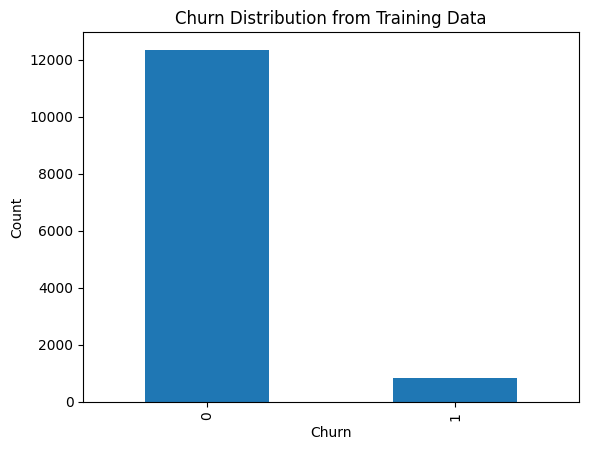

In [149]:
# visualizing the churn target distribution
data['churn_target'].value_counts().plot(kind='bar')
plt.title('Churn Distribution from Training Data')
plt.xlabel('Churn')
plt.ylabel('Count')

## Multivariate analysis:

In [150]:
# Calculate correlations with the target variable, excluding User_Id
correlations = data.drop(columns=['User_Id']).corr()['churn_target'].apply(lambda x : abs(x)).sort_values(ascending=False)

# Display the correlations
print(correlations)

KeyError: "['User_Id'] not found in axis"

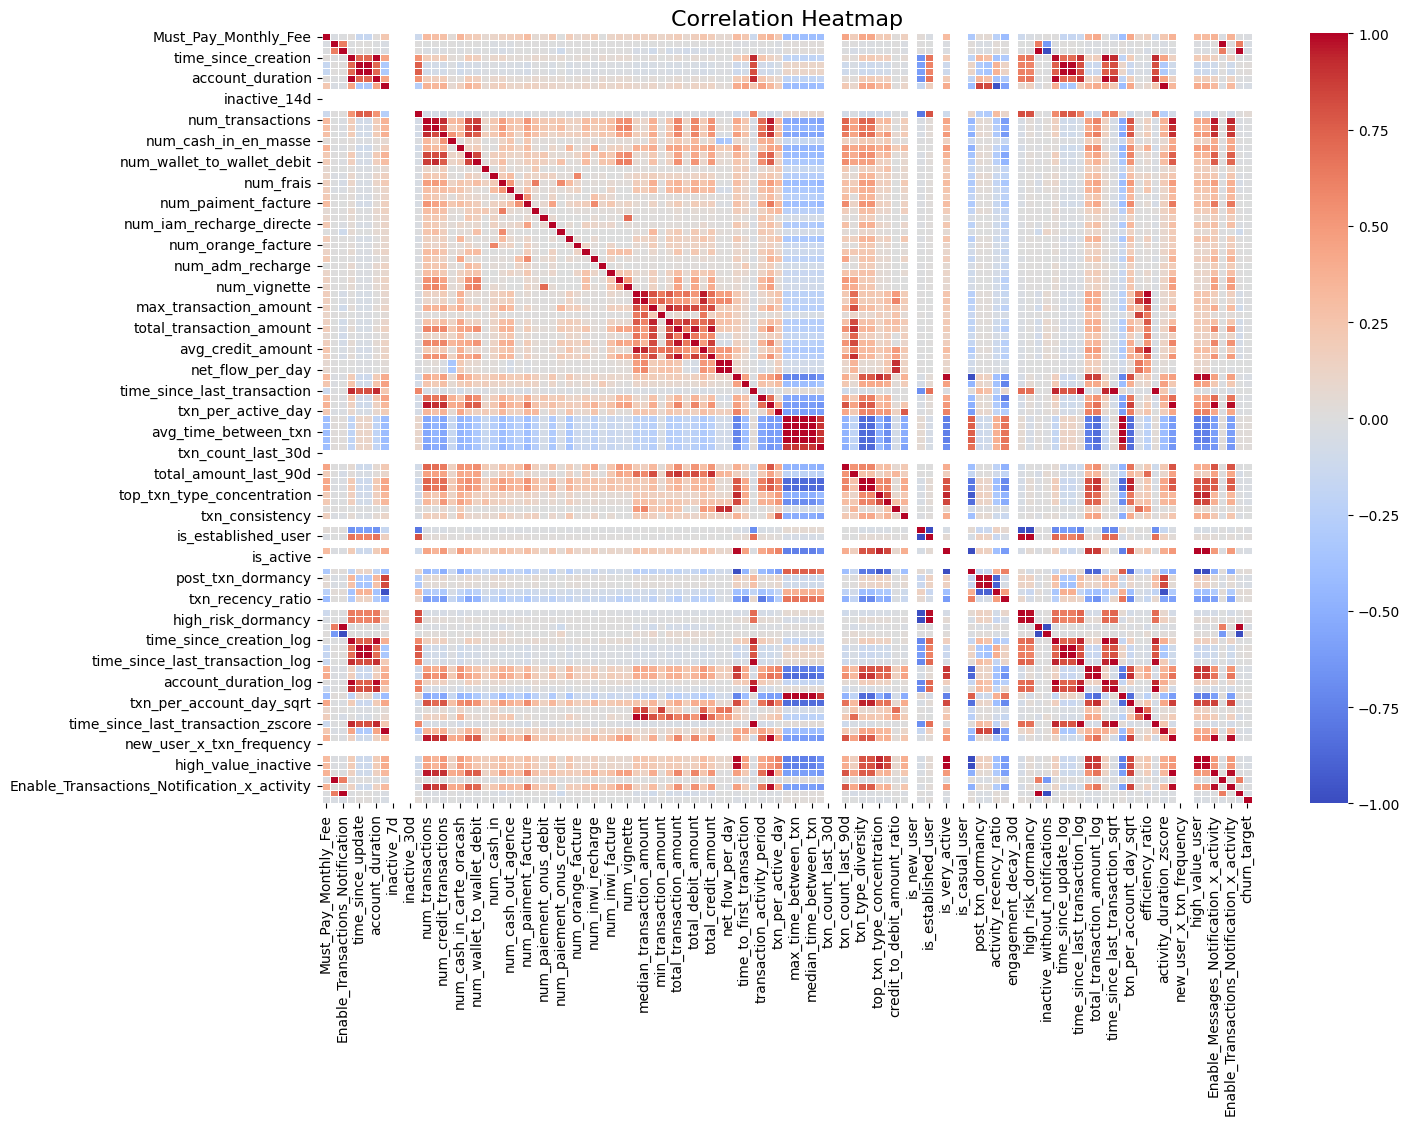

In [153]:
import seaborn as sns

import matplotlib.pyplot as plt

# Compute the correlation matrix
correlation_matrix = data.corr()

# Set up the matplotlib figure
plt.figure(figsize=(15, 10))

# Draw the heatmap
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt='.2f', linewidths=0.5)

# Add title
plt.title('Correlation Heatmap', fontsize=16)

# Show the plot
plt.show()

In [154]:
# Calculate correlations with the target variable, excluding User_Id
num_col = data.select_dtypes(include=['number']).columns.tolist()
data = data[num_col]

### Correlation Matrix Results

The correlation matrix provides insights into the relationships between numerical features in the dataset. Each cell in the matrix represents the correlation coefficient between two variables, ranging from -1 to 1:

- **Positive Correlation (close to 1):** Indicates that as one variable increases, the other tends to increase as well.
- **Negative Correlation (close to -1):** Indicates that as one variable increases, the other tends to decrease.
- **No Correlation (close to 0):** Indicates no linear relationship between the variables.

#### Key Observations:
1. **Churn Target Correlations:**
    - Features like `account_duration`, `activity_duration`, and `time_since_last_update` may show significant correlations with `churn_target`. For example:
      - A **positive correlation** with `time_since_last_update` might indicate that users who haven't updated their accounts recently are more likely to churn.
      - A **negative correlation** with `activity_duration` might suggest that users with longer activity durations are less likely to churn.

2. **Transaction Features:**
    - Features such as `num_transactions`, `total_transaction_amount`, and `transaction_activity_period` may have correlations with each other, as they all relate to user transaction behavior.
    - A **positive correlation** between `num_transactions` and `total_transaction_amount` is expected, as more transactions typically result in higher total amounts.

3. **Wallet and Notification Features:**
    - Features like `Enable_Transactions_Notification` and `Enable_Messages_Notification` might show weak or no correlation with `churn_target`, indicating that enabling notifications alone may not strongly influence churn.

4. **Multicollinearity:**
    - Some features, such as `avg_transaction_amount`, `max_transaction_amount`, and `min_transaction_amount`, may exhibit high correlations with `total_transaction_amount`, indicating potential multicollinearity. This could affect model performance and may require dimensionality reduction techniques like PCA or feature selection.

5. **Gender and Language Features:**
    - Encoded categorical features like `Gender_MALE` and `Language_en` may show weak correlations with `churn_target`, as demographic factors might have limited influence on churn.

In [155]:
data.shape

(13203, 111)

In [156]:
data.columns

Index(['Must_Pay_Monthly_Fee', 'Enable_Messages_Notification',
       'Enable_Transactions_Notification', 'time_since_creation',
       'time_since_update', 'time_since_last_online', 'account_duration',
       'activity_duration', 'inactive_7d', 'inactive_14d',
       ...
       'txn_per_account_day_zscore', 'new_user_x_txn_frequency',
       'mature_user_x_decay', 'high_value_user', 'high_value_inactive',
       'Enable_Messages_Notification_x_activity',
       'Enable_Messages_Notification_x_dormancy',
       'Enable_Transactions_Notification_x_activity',
       'Enable_Transactions_Notification_x_dormancy', 'churn_target'],
      dtype='object', length=111)

In [157]:
data.head()

,Must_Pay_Monthly_Fee,Enable_Messages_Notification,Enable_Transactions_Notification,time_since_creation,time_since_update,time_since_last_online,account_duration,activity_duration,inactive_7d,inactive_14d,...,txn_per_account_day_zscore,new_user_x_txn_frequency,mature_user_x_decay,high_value_user,high_value_inactive,Enable_Messages_Notification_x_activity,Enable_Messages_Notification_x_dormancy,Enable_Transactions_Notification_x_activity,Enable_Transactions_Notification_x_dormancy,churn_target
0,0,1,1,114.068824,114.066040,114.066040,114.068824,0.002784,1,1,...,-0.09427,0.0,0,0,0,0.0,1,0.0,1,0
1,0,1,1,78.823211,78.821370,78.821371,78.823211,0.001841,1,1,...,-0.09427,0.0,0,0,0,0.0,1,0.0,1,0
2,0,1,1,117.700576,113.043172,113.043173,117.700576,4.657403,1,1,...,-0.09427,0.0,0,0,0,0.0,1,0.0,1,0
3,0,1,1,181.393085,181.375740,181.375740,181.393085,0.017345,1,1,...,-0.09427,0.0,0,0,0,0.0,1,0.0,1,0
4,0,1,1,121.108447,120.389945,120.389946,121.108447,0.718502,1,1,...,-0.09427,0.0,0,0,0,0.0,1,0.0,1,0


<Axes: >

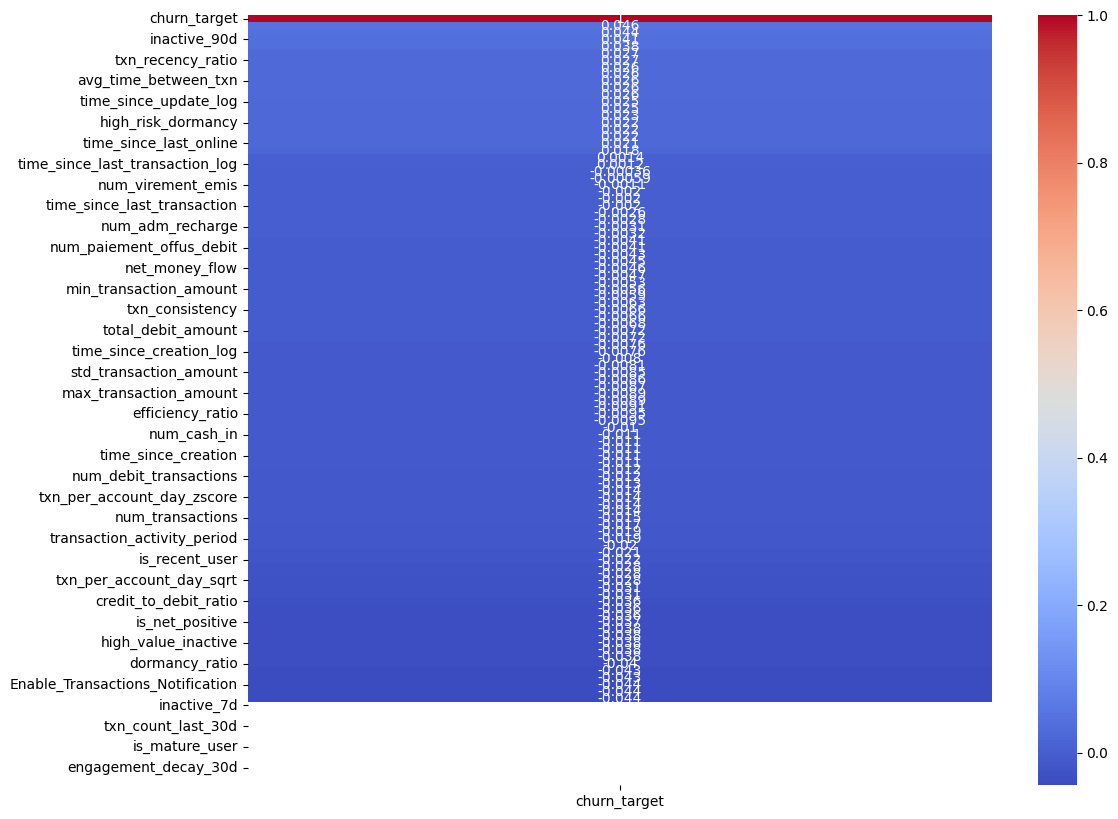

In [158]:


plt.figure(figsize=(12, 10))
sns.heatmap(data.corr(numeric_only=True)[['churn_target']].sort_values(by='churn_target', ascending=False), annot=True, cmap='coolwarm')


In [159]:
# Save the data to a CSV file
data.to_csv('Ora_Data.csv', index=False)

### Conclusion

The exploratory data analysis (EDA) provided valuable insights into the user and transaction datasets, enabling us to clean, preprocess, and engineer meaningful features. Key steps included handling missing values, encoding categorical variables, and creating new features such as transaction activity and churn indicators. These efforts have prepared the data for the next phase of the project.

### Next Steps

In the next phase, we will transition to machine learning, where we will build and evaluate predictive models to identify at-risk users. This phase will be documented in the `ML_phase.ipynb` notebook. The focus will be on selecting appropriate algorithms, optimizing model performance, and deriving actionable insights to reduce user churn.

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, make_scorer
import numpy as np
import pandas as pd

# 1. Split data
X = data.drop(columns=['churn_target'])
y = data['churn_target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 2. Define Random Forest model with class_weight to handle imbalance
rf = RandomForestClassifier(class_weight='balanced', random_state=42)

# 3. Setup parameter grid for tuning
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

# Use F1 score as the metric
f1 = make_scorer(f1_score)

# 4. Grid Search with cross-validation
grid_search = GridSearchCV(
    rf,
    param_grid,
    scoring=f1,
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# 5. Best model
best_rf = grid_search.best_estimator_

# 6. Evaluate on test data
y_pred = best_rf.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 7. Feature importance
importances = best_rf.feature_importances_
indices = np.argsort(importances)[::-1]

print("\nTop 10 Feature Importances:")
for i in range(10):
    print(f"{i+1}. {X.columns[indices[i]]}: {importances[indices[i]]:.4f}")

Fitting 5 folds for each of 72 candidates, totalling 360 fits

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.72      0.82      2470
           1       0.08      0.37      0.14       171

    accuracy                           0.70      2641
   macro avg       0.51      0.55      0.48      2641
weighted avg       0.89      0.70      0.77      2641


Confusion Matrix:
[[1779  691]
 [ 107   64]]

Top 10 Feature Importances:
1. post_txn_dormancy: 0.0722
2. activity_duration: 0.0718
3. activity_recency_ratio: 0.0654
4. activity_duration_zscore: 0.0625
5. dormancy_ratio: 0.0606
6. time_since_last_online: 0.0499
7. account_duration_log: 0.0496
8. time_since_update: 0.0492
9. time_since_last_transaction_log: 0.0475
10. time_since_last_online_log: 0.0475
